![Banner](../images/09_04_banner_rs_uav.png)


# DEM Correction and Canopy Height

Plant height is one of the most useful traits a drone can measure, and it comes from the
elevation models of notebook 09_04_03.


## Overview

Without ground control points or RTK, the elevation models from notebook 09_04_03 bend. Structure-from-Motion trades lens distortion against camera height and leaves a **dome or bowl**, often with a tilt, that can be larger than the crop itself. The LUMS study removed it with RANSAC polynomial fitting (`code/dem_post_processing/ransac_flatten.py`) and reached R = 0.876 and MAE = 0.177 m against ruler heights. This notebook rebuilds that workflow with `rs.uav.ransac_flatten`, applies it consistently across dates, derives canopy height and validates plot heights against reference values.


## Core concepts

### Learning objectives

1. Recognise doming, bowl and tilt artefacts in GCP-free DEMs and measure them.
2. Fit a RANSAC polynomial trend surface and choose its degree.
3. Apply one correction consistently to a multi-date DEM series, and know when per-date
   fitting is better.
4. Derive canopy height (flattened DEM above ground, or `rs.uav.chm_from_surfaces`).
5. Summarise height per plot and validate against field measurements (R, MAE, bias).

### Data

| Data | Type |
|---|---|
| Synthetic 3 × 5 plot rice DEMs, 2 cm, five dates from 4 Sep to 3 Oct 2025 (`rs.uav.synthetic_dem`) | **Simulated** (true canopy height is known) |
| LUMS DEMs | Not in the public release. Set `DEM_PATHS` to run the same code on real models |

### Contents

1. Setup
2. A season of GCP-free DEMs
3. Fitting the trend surface with RANSAC
4. One correction for all dates
5. Canopy height
6. Plot heights and validation
7. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled arrays
import matplotlib.pyplot as plt  # figures
from scipy import ndimage as ndi  # labelling plots, percentiles per zone

import geolattice.rsense as rs  # GeoLattice remote sensing (rs.uav = drone tools)

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
DEM_PATHS = None  # e.g. sorted(Path("dems").glob("*_dem.tif")) for real LUMS DEMs

## A season of GCP-free DEMs

Five dates, canopy growing from 0.45 m to 1.0 m. Each date gets its own dome (1.0 to 1.4 m
between centre and corners) and tilt, as separate SfM runs never bend identically, plus 2 cm
noise. The first date also has a nodata border of -32767, a common photogrammetry fill value.


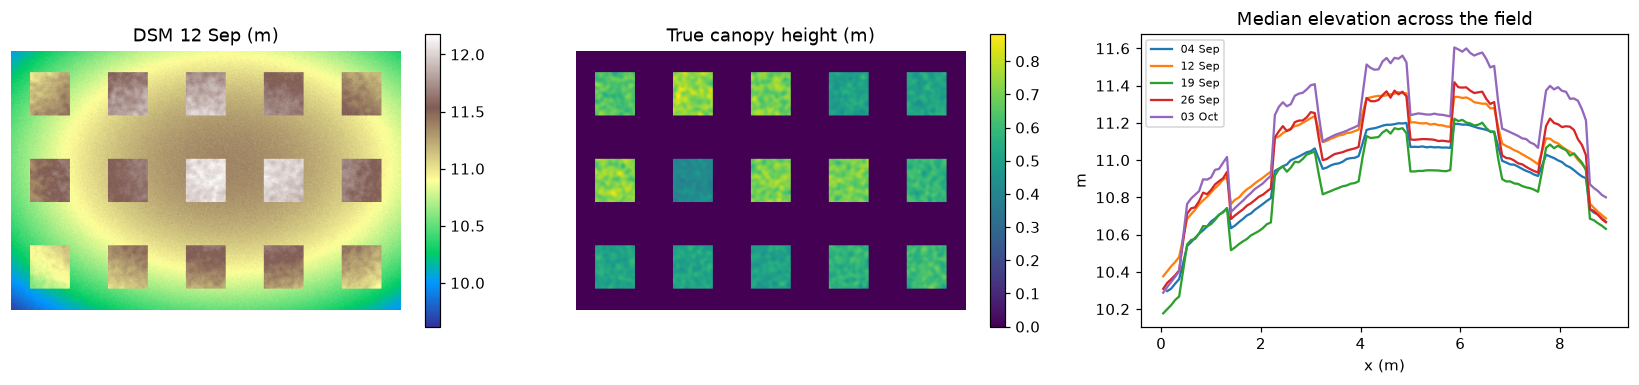

In [2]:
dates = pd.to_datetime(["2025-09-04", "2025-09-12", "2025-09-19", "2025-09-26", "2025-10-03"])
heights = [0.45, 0.60, 0.75, 0.90, 1.00]  # mean canopy height (m) on each date
domes = [1.20, 1.35, 1.05, 1.25, 1.40]    # dome amplitude (m)
tilts = [(0.40, -0.25), (0.30, -0.35), (0.45, -0.15), (0.35, -0.30), (0.50, -0.20)]
rng = np.random.default_rng(42)

dsms, chms_true = [], []
for h, dome, tilt in zip(heights, domes, tilts):
    dsm, chm = rs.uav.synthetic_dem((300, 450), gsd=0.02, canopy_height=h, doming=dome, tilt=tilt,
                                    noise=0.0, seed=7)  # same plots and texture every date
    dsm = dsm + rng.normal(0, 0.02, dsm.shape).astype("float32")  # fresh noise each date
    dsms.append(dsm); chms_true.append(chm)
dsms[0][:, :6] = -32767.0  # nodata strip on the first date
if DEM_PATHS:  # real data replace the synthetic ones
    dsms = [rs.core.read(p).squeeze("band", drop=True) for p in DEM_PATHS]
    chms_true = None

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
im = axes[0].imshow(dsms[1], cmap="terrain"); axes[0].set_title(f"DSM {dates[1]:%d %b} (m)"); plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(chms_true[1], cmap="viridis"); axes[1].set_title("True canopy height (m)"); plt.colorbar(im, ax=axes[1])
for d, dsm in zip(dates, dsms):
    prof = rs.uav.doming_profile(dsm.where(dsm > -200), axis="x")
    axes[2].plot(prof.x, prof, label=f"{d:%d %b}")
axes[2].set(title="Median elevation across the field", xlabel="x (m)", ylabel="m"); axes[2].legend(fontsize=7)
for a in axes[:2]: a.axis("off")
plt.tight_layout(); plt.show()

The dome (about a metre) dwarfs the crop (under a metre), and it differs between dates, so
subtracting two raw DSMs does not give growth either.


## Fitting the trend surface with RANSAC

A polynomial surface $z = f(\text{col}, \text{row})$ is fitted to the DEM. Ordinary least
squares would be pulled up by the plants; RANSAC repeatedly fits random subsets and keeps the
model that most pixels agree with. **It locks onto whichever surface is the majority**, so
with bare alleys between plots (here about 75 % of pixels) it fits the ground. Under a closed
canopy it would fit the canopy top instead, which still removes the dome (a level canopy
stays level) but gives height relative to the canopy, not the ground.


In [3]:
dem = dsms[1]
rows = []
for deg in [1, 2, 3, 4]:
    surf, info = rs.uav.trend_surface(dem, degree=deg)
    resid = dem.values - surf
    ground = chms_true[1].values == 0
    rows.append({"degree": deg, "inlier_frac": info["inlier_frac"], "trend_range_m": info["trend_range"],
                 "ground_residual_sd_m": float(np.std(resid[ground]))})
pd.DataFrame(rows).round(4)

,degree,inlier_frac,trend_range_m,ground_residual_sd_m
0,1,0.5020,0.7570,0.3054
1,2,0.7444,1.6949,0.0200
2,3,0.7444,1.6954,0.0200
3,4,0.5448,1.5802,0.2708


Degree 1 (a plane) removes only tilt and leaves 30 cm of dome in the ground. Degree 2 captures
the dome and leaves only the 2 cm noise. Degree 3 adds nothing, and degree 4 is worse: with
more terms RANSAC's random minimal samples more often mix ground and canopy pixels, and real
fields add furrows and sloping corners a flexible surface would follow. The LUMS script uses
degree 2, the default of `ransac_flatten`.


## One correction for all dates

`rs.uav.ransac_flatten(dems, degree=2, reference=0)` follows the LUMS script:

1. mask nodata (`edge_threshold`, -200 by default) and keep pixels valid in every date;
2. fit the trend on the reference date only;
3. subtract the same trend from every date and match each date's mean to the reference;
4. `normalize="ground"` subtracts a season-wide low percentile so bare soil sits at 0 m
   (`normalize="lums"` reproduces the script's 0-5 rescaling instead, which is unitless).


In [4]:
lums = rs.uav.ransac_flatten(dsms, degree=2, reference=0, normalize="ground", ground_percentile=5)
print("fit info:", {k: round(v, 3) if isinstance(v, float) else v for k, v in lums.info.items()})
print("ground level removed:", round(lums.ground, 3), "m")

fit info: {'degree': 2, 'inlier_frac': 0.741, 'trend_range': 1.512, 'reference': 0, 'normalize': 'ground', 'match': 'mean'}
ground level removed: -0.174 m


Step 3 hides a trap. Matching each date's **mean** to the reference assumes the mean surface
does not change between flights, but a growing canopy raises it, so every later date is
pulled down by part of its own growth. `match="ground"` levels the dates on a low percentile
(bare soil) instead. A third option is to fit a separate trend for each date, which also
handles domes that differ between flights.


In [5]:
shared = rs.uav.ransac_flatten(dsms, degree=2, reference=0, normalize="ground", ground_percentile=5, match="ground")
per_date = [rs.uav.ransac_flatten([d], degree=2, normalize="ground", ground_percentile=5).dems[0] for d in dsms]
variants = {"LUMS (shared, mean match)": lums.dems, "shared, ground match": shared.dems, "per-date trend": per_date}

def ground_err(flat, truth):
    """Bias and spread of flattened bare-soil pixels (should be 0 m)."""
    g = (truth.values == 0) & np.isfinite(flat.values)
    return float(np.mean(flat.values[g])), float(np.std(flat.values[g]))

tab = []
for i, d in enumerate(dates):
    row = {"date": d.date()}
    for name, dems in variants.items():
        b, sd = ground_err(dems[i], chms_true[i])
        row[(name, "bias")], row[(name, "SD")] = b, sd
    tab.append(row)
gt = pd.DataFrame(tab).set_index("date"); gt.columns = pd.MultiIndex.from_tuples(gt.columns)
gt.round(3)

LUMS (shared, mean match)        shared, ground match         \
                                bias     SD                 bias     SD   
date                                                                      
2025-09-04                     0.174  0.020                0.030  0.020   
2025-09-12                     0.134  0.057                0.092  0.057   
2025-09-19                     0.098  0.051                0.064  0.051   
2025-09-26                     0.058  0.031                0.049  0.031   
2025-10-03                     0.032  0.057                0.093  0.057   

           per-date trend        
                     bias    SD  
date                             
2025-09-04           0.03  0.02  
2025-09-12           0.03  0.02  
2025-09-19           0.03  0.02  
2025-09-26           0.03  0.02  
2025-10-03           0.03  0.02

Reading the table:

* **Mean matching** gives bare soil a bias that shrinks date by date (the reference date
  ends up too high, the late dates are pulled down): exactly the growth it removed.
* **Ground matching** removes that steady drift. What remains (a few centimetres, varying by
  date, and the larger SD) is the part of each date's own dome that differs from the
  reference dome, which no shared trend can remove.
* **Per-date fitting** is cleanest when every flight bends differently. When doming is
  similar between flights (same drone, altitude and pattern) a shared fit is the safer
  choice, because it cannot absorb a genuine change in the field into the trend. Inspect the
  ground residuals before choosing.


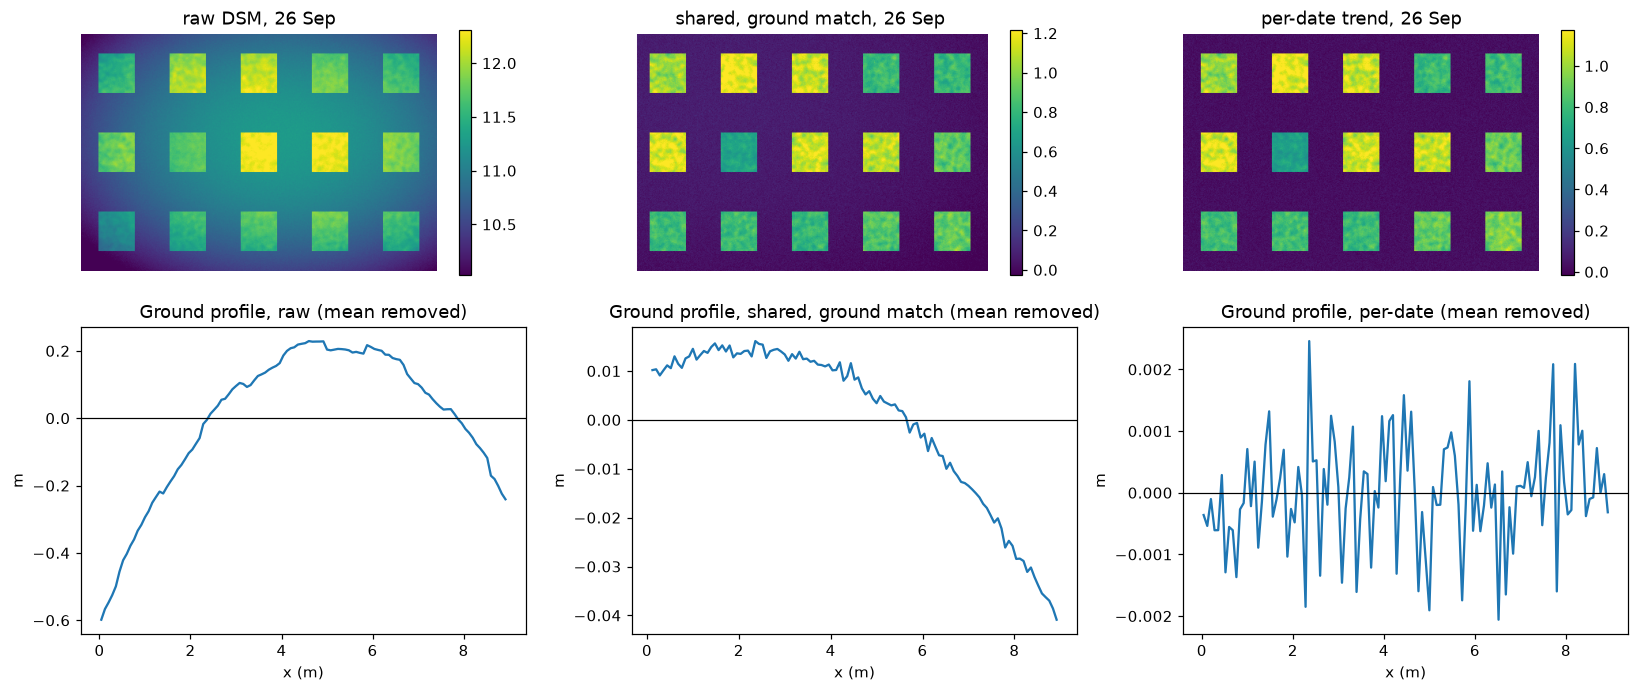

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.5))
for ax, (title, arr) in zip(axes[0], [("raw DSM", dsms[3]), ("shared, ground match", shared.dems[3]), ("per-date trend", per_date[3])]):
    a = arr.where(arr > -200)
    im = ax.imshow(a, cmap="viridis", vmin=float(a.quantile(0.01)), vmax=float(a.quantile(0.99)))
    ax.set_title(f"{title}, {dates[3]:%d %b}"); ax.axis("off"); plt.colorbar(im, ax=ax, shrink=0.8)
for ax, (title, arr) in zip(axes[1], [("raw", dsms[3]), ("shared, ground match", shared.dems[3]), ("per-date", per_date[3])]):
    prof = rs.uav.doming_profile(arr.where((arr > -200) & (chms_true[3] == 0)), axis="x")
    ax.plot(prof.x, prof - float(prof.mean())); ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"Ground profile, {title} (mean removed)", xlabel="x (m)", ylabel="m")
plt.tight_layout(); plt.show()

## Canopy height

After `normalize="ground"`, the flattened DEM **is** height above ground, with a small
positive bias because a low percentile of noisy ground sits slightly below the true ground.
If a bare-soil DEM from before planting (or a DTM) exists, `rs.uav.chm_from_surfaces(dsm,
dtm)` subtracts it instead; both inputs must be flattened the same way. Here the median of
the flattened bare soil stands in for that DTM, which removes the bias.


In [7]:
chm = per_date[3].clip(min=0).where(np.isfinite(per_date[3]))
dtm = per_date[3].where(chms_true[3] == 0)
dtm = dtm.fillna(float(dtm.median()))  # a smooth bare-ground surface (here: flat after correction)
chm2 = rs.uav.chm_from_surfaces(per_date[3], dtm)
for name, c in [("flattened DEM above ground", chm), ("chm_from_surfaces(DSM, DTM)", chm2)]:
    err = (c - chms_true[3]).values
    print(f"{name:28s} bias {np.nanmean(err):+.3f} m, RMSE {np.sqrt(np.nanmean(err**2)):.3f} m")

flattened DEM above ground   bias +0.030 m, RMSE 0.036 m
chm_from_surfaces(DSM, DTM)  bias -0.000 m, RMSE 0.010 m


## Plot heights and validation

Field teams measure plant height with a ruler at a handful of plants per plot. The UAV
equivalent is a high percentile of the CHM inside each plot (the canopy top, not the mean,
which includes gaps between plants). Plots are found here by labelling the true canopy; with
real data you would rasterise plot polygons instead.


15 plots


,R,MAE_m,bias_m,n
"LUMS (shared, mean match)",0.964,0.109,0.104,75.0
"shared, ground match",0.974,0.074,0.071,75.0
per-date trend,0.984,0.047,0.032,75.0


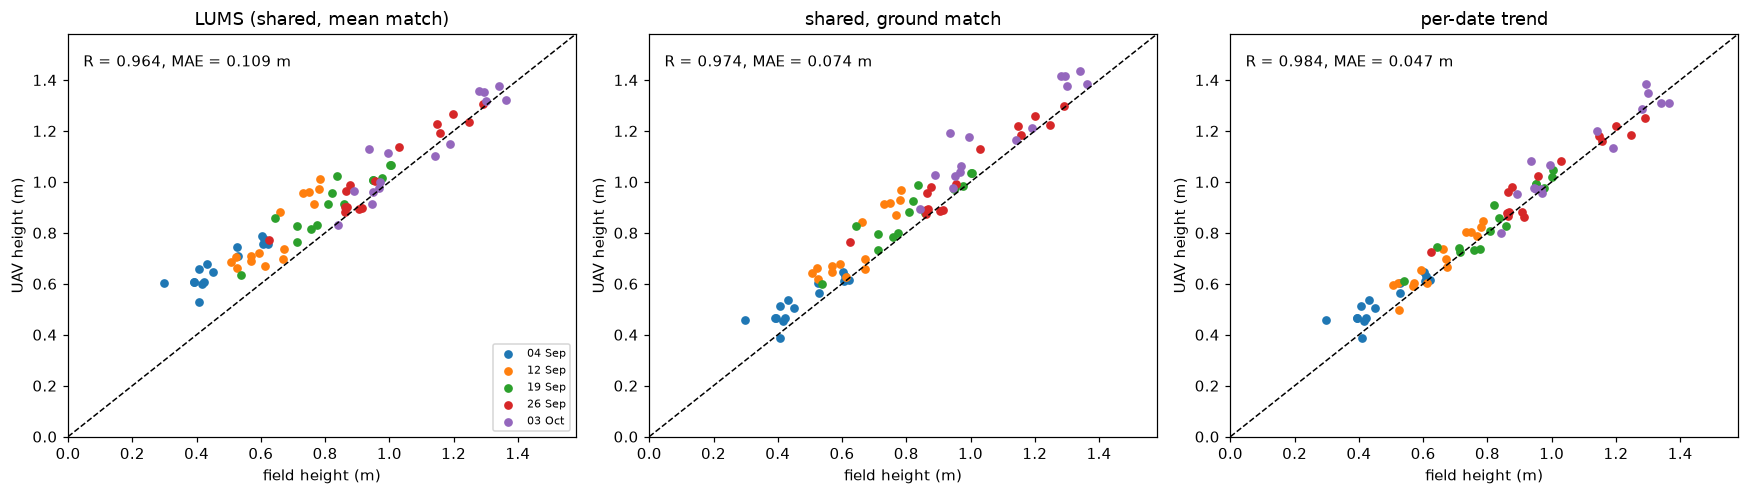

In [8]:
zones, n_plots = ndi.label(chms_true[0].values > 0)
print(n_plots, "plots")

def plot_heights(chm_arr, zones, q=95):
    """q-th percentile of canopy height in each plot."""
    return np.array([np.nanpercentile(chm_arr[zones == z], q) for z in range(1, zones.max() + 1)])

rng_field = np.random.default_rng(0)
records = []
for i, (d, t) in enumerate(zip(dates, chms_true)):
    truth = plot_heights(t.values, zones)
    field = truth + rng_field.normal(0, 0.05, truth.size)  # ruler readings: +/- 5 cm
    est = {name: plot_heights(dems[i].values, zones) for name, dems in variants.items()}
    for z in range(n_plots):
        records.append({"date": d, "plot": z + 1, "field_m": field[z], **{name: e[z] for name, e in est.items()}})
val = pd.DataFrame(records)

def scores(obs, est):
    r = np.corrcoef(obs, est)[0, 1]
    return {"R": r, "MAE_m": np.mean(np.abs(est - obs)), "bias_m": np.mean(est - obs), "n": len(obs)}

display(pd.DataFrame({name: scores(val.field_m, val[name]) for name in variants}).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, col in zip(axes, variants):
    for d, g in val.groupby("date"):
        ax.scatter(g.field_m, g[col], s=22, label=f"{d:%d %b}")
    lim = [0, val[["field_m", *variants]].max().max() * 1.1]
    ax.plot(lim, lim, "k--", lw=1); ax.set(xlim=lim, ylim=lim, xlabel="field height (m)", ylabel="UAV height (m)", title=col)
    s_ = scores(val.field_m, val[col]); ax.text(0.03, 0.92, f"R = {s_['R']:.3f}, MAE = {s_['MAE_m']:.3f} m", transform=ax.transAxes)
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

For comparison, LUMS reported R = 0.876 and MAE = 0.177 m on real rice. Real errors are
larger than in this synthetic test because leaves move in the wind between frames, thin
panicles are missed by dense matching, and ruler readings and DEM pixels never sample the
same plants.

**Growth curves.** Mean plot height per date for each method; note how mean matching
flattens the curve:


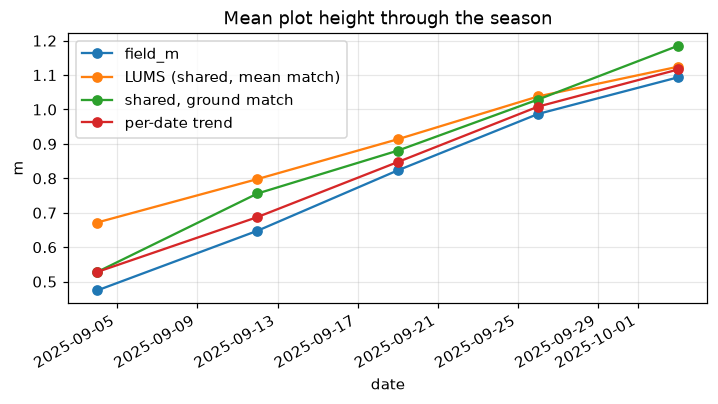

In [9]:
growth = val.groupby("date")[["field_m", *variants]].mean()
ax = growth.plot(marker="o", figsize=(7.5, 3.6), title="Mean plot height through the season")
ax.set_ylabel("m"); ax.grid(alpha=0.3); plt.show()
val.to_csv(OUT / "plot_heights_validation.csv", index=False)

## Summary and exercises

**Key points**

- Without GCP or RTK, a Structure-from-Motion DEM domes, bowls and tilts. The bend can be
  taller than the crop.
- RANSAC fits a polynomial to ground points and subtracts it. Look at the degree and the
  inliers; a default is not a check.
- Use one shared surface across dates when the dome is stable. Fit each date when it is not.
- Plot height is a high percentile of the flattened surface. Report it against field heights
  as R, MAE and bias.

**GeoLattice functions used:** `rs.uav.synthetic_dem`, `rs.uav.doming_profile`, `rs.uav.trend_surface`,
`rs.uav.ransac_flatten`, `rs.uav.chm_from_surfaces`.

**Exercises**

1. Set `plot_gap=0.1` in `synthetic_dem` (a nearly closed canopy). What does RANSAC fit now,
   and what happens to the plot heights after `normalize="ground"`?
2. Make all five domes equal (1.2 m). Is the shared, ground-matched trend now as good as the
   per-date one? Is mean matching still biased?
3. Replace the 95th percentile with the mean and the 99th percentile in `plot_heights`. Which
   gives the smallest bias against field heights, and why?
4. Run `ransac_flatten(..., normalize="lums")` and compare its output range with the LUMS
   script. Why are those values not metres?

**References**

- Chaudhry, H., Rana, S. and Jaleel, A. (2026). UAV-based crop reconstruction and trait
  estimation using RGB imagery without external geospatial infrastructure. *Computers and
  Electronics in Agriculture* (accepted).
- James, M. R. and Robson, S. (2014). Mitigating systematic error in topographic models derived
  from UAV and ground-based image networks. *Earth Surface Processes and Landforms*, 39,
  1413-1420.
- Fischler, M. A. and Bolles, R. C. (1981). Random sample consensus. *Communications of the
  ACM*, 24, 381-395.
- Bendig, J. et al. (2014). Estimating biomass of barley using crop surface models (CSMs)
  derived from UAV-based RGB imaging. *Remote Sensing*, 6, 10395-10412.
